In [11]:
import pickle

acc_1 = []
acc_2 = []
acc_3 = []
for i in range(1, 7):
    acc1 = []
    with open(f"pkl_colorectal_non_msk/month_{i}__n_features_1__top10pct.pkl", "rb") as f:
        while True:
            try:
                res = pickle.load(f)
                acc1.append(res["accuracy"])
            except EOFError:
                break
    acc_1.append(acc1)

    acc2 = []
    with open(f"pkl_colorectal_non_msk/month_{i}__n_features_2__top10pct.pkl", "rb") as f:
        while True:
            try:
                res = pickle.load(f)
                acc2.append(res["accuracy"])
            except EOFError:
                break
    acc_2.append(acc2)

    acc3 = []
    with open(f"pkl_colorectal_non_msk/month_{i}__n_features_3__top10pct.pkl", "rb") as f:
        while True:
            try:
                res = pickle.load(f)
                acc3.append(res["accuracy"])
            except EOFError:
                break
    acc_3.append(acc3)

/mnt/scratch/k_dobrovolskaya/defense_systems/syntons/.venv/lib/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [7]:
import pandas as pd

boosting_accuracies = []
for i in range(1, 7):
    acc_boosting = []
    for j in range(10):
        df = pd.read_csv(f"full_models_output/month_{i}__boosting__rs{j}__trials.tsv", sep="\t")
        acc_boosting.append(df["value"].max())
    boosting_accuracies.append(acc_boosting)

logreg_accuracies = []
for i in range(1, 7):
    acc_logreg = []
    for j in range(10):
        df = pd.read_csv(f"full_models_output/month_{i}__logreg__rs{j}__trials.tsv", sep="\t")
        acc_logreg.append(df["value"].max())
    logreg_accuracies.append(acc_logreg)

In [13]:
import pickle

def comparative_accuracy(moscow_dir, extra_dir, feature):
    acc_1 = []
    acc_2 = []
    for i in range(1, 7):
        acc1 = []
        with open(f"{moscow_dir}/month_{i}__n_features_{feature}__top10pct.pkl", "rb") as f:
            while True:
                try:
                    res = pickle.load(f)
                    acc1.append(res["accuracy"])
                except EOFError:
                    break
        acc_1.append(acc1)
    
        acc2 = []
        with open(f"{extra_dir}/month_{i}__n_features_{feature}__top10pct.pkl", "rb") as f:
            while True:
                try:
                    res = pickle.load(f)
                    acc2.append(res["accuracy"])
                except EOFError:
                    break
        acc_2.append(acc2)
    cut_len = [min(len(x), len(y)) for x, y in zip(acc_1, acc_2)]
    acc_1 = [sorted(acc_1[i], reverse=True)[:cut_len[i]] for i in range(len(acc_1))]
    acc_2 = [sorted(acc_2[i], reverse=True)[:cut_len[i]] for i in range(len(acc_2))]
    return acc_1, acc_2

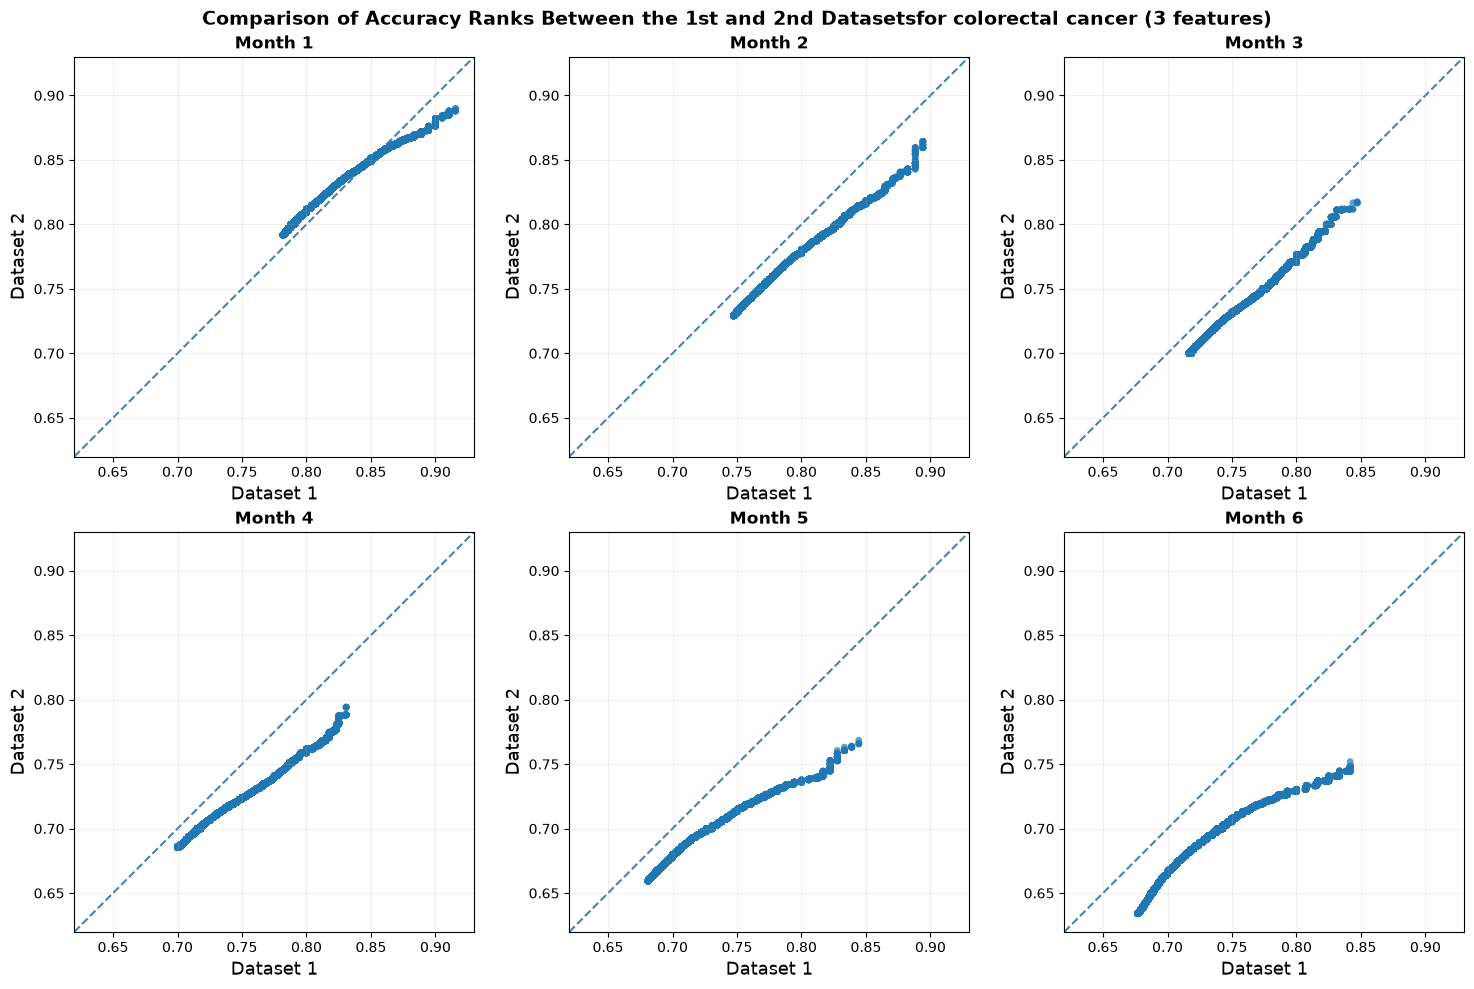

In [21]:
import numpy as np
import matplotlib.pyplot as plt

n_feature = 3

colorectal_1_m, colorectal_1 = comparative_accuracy(
    "colorectal_cancer_output",
    "pkl_colorectal_non_msk",
    n_feature
)


fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 10),
)

axes = axes.ravel()

for i in range(6):
    x = np.asarray(colorectal_1_m[i], dtype=float)
    y = np.asarray(colorectal_1[i], dtype=float)

    ax = axes[i]

    ax.scatter(
        x,
        y,
        s=25,
        alpha=0.7,
        edgecolors="none",
    )

    # Общий диапазон для X и Y
    xy_min = min(x.min(), y.min())
    xy_max = max(x.max(), y.max())

    # Небольшой запас
    margin = 0.01
    xy_min -= margin
    xy_max += margin

    # Линия y = x
    ax.plot(
        # [xy_min, xy_max],
        # [xy_min, xy_max],
        [0.62, 0.93],
        [0.62, 0.93],
        linestyle="--",
        linewidth=1.5,
        color="steelblue",
        zorder=0,
    )

    ax.set_title(f"Month {i + 1}", fontweight="bold")
    ax.set_xlabel("Dataset 1", fontsize=13)
    ax.set_ylabel("Dataset 2", fontsize=13)

    # Одинаковый диапазон по X и Y
    # ax.set_xlim(xy_min, xy_max)
    # ax.set_ylim(xy_min, xy_max)

    ax.set_xlim(0.62, 0.93)
    ax.set_ylim(0.62, 0.93)

    # Одинаковый масштаб единицы X и Y
    ax.set_aspect("equal", adjustable="box")

    ax.grid(alpha=0.2)

plt.suptitle(
    "Comparison of Accuracy Ranks Between the 1st and 2nd Datasets"
    f"for colorectal cancer ({n_feature} features)",
    fontsize=14,
    fontweight="bold",
)

plt.tight_layout()
plt.savefig(f"Rang_compares_colorectal_{n_feature}", dpi=300)
plt.show()

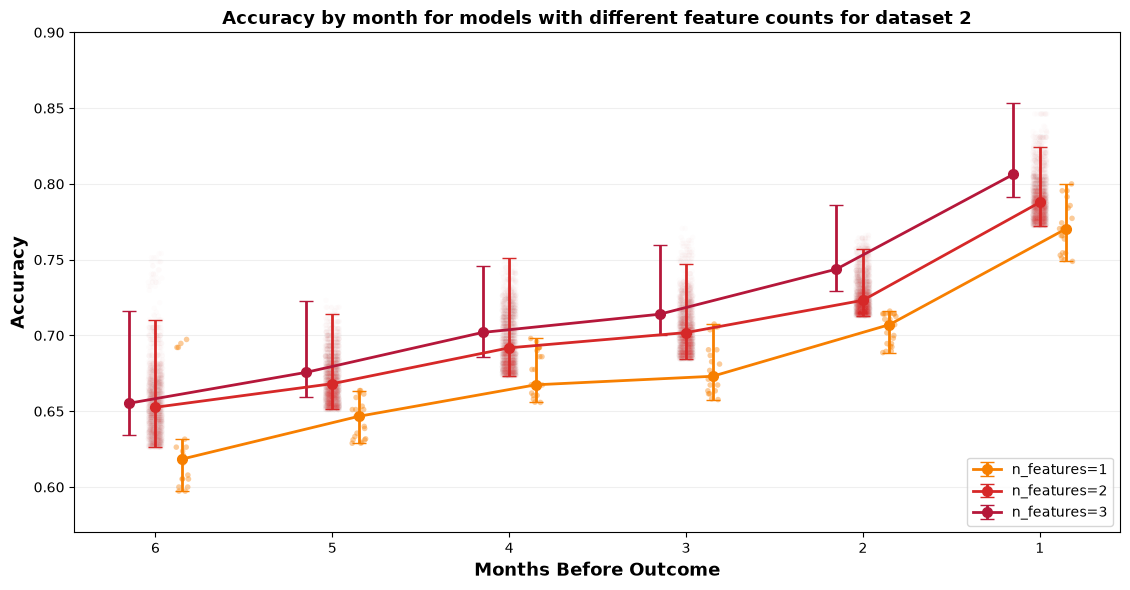

(<Figure size 1140x600 with 1 Axes>,
 <Axes: title={'center': 'Accuracy by month for models with different feature counts for dataset 2'}, xlabel='Months Before Outcome', ylabel='Accuracy'>)

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from typing import Dict, Optional, Sequence

COLORS = {
    "n_features=1": "#F77F00",          # оранжевый
    "n_features=2": "#D62828",           # красный
    "n_features=3": "#B5173A",           # малиновый
    "LogReg (all features)": "#277DA1",  # синий
    "Boosting (all features)": "#006400" # тёмно-зелёный
}

def _median_iqr_whiskers(accs):
    arr = np.asarray(accs, dtype=float)
    arr = arr[np.isfinite(arr)]

    if arr.size == 0:
        return np.nan, np.nan, np.nan

    median = np.median(arr)
    q25, q75 = np.percentile(arr, [25, 75])

    iqr = q75 - q25
    lo_bound = q25 - 1.5 * iqr
    hi_bound = q75 + 1.5 * iqr

    inside = arr[(arr >= lo_bound) & (arr <= hi_bound)]

    lo = inside.min() if inside.size else q25
    hi = inside.max() if inside.size else q75

    return median, max(0, median - lo), max(0, hi - median)


def plot_accuracy_by_month(
    series: Dict[str, Sequence[Sequence[float]]],
    month_labels: Optional[Sequence] = None,
    show_points: bool = True,
    title: str = "Accuracy by month for models with different feature counts for dataset 2",
    output_path: Optional[str] = None,
    show: bool = True,
):
    n_series = len(series)
    n_months = len(next(iter(series.values())))

    if month_labels is None:
        month_labels = list(range(1, n_months + 1))

    x = np.arange(n_months)
    offsets = np.linspace(-0.15, 0.15, n_series)

    fig, ax = plt.subplots(figsize=(1.4 * n_months + 3, 6))
    rng = np.random.default_rng(42)

    point_alpha = {
        "n_features=1": 0.4,
        "n_features=2": 0.01,
        "n_features=3": 0.001,
        "Boosting (all features)": 0.15,
        "LogReg (all features)": 0.15,
    }
    
    for name, accs_per_month in series.items():
        color = COLORS[name]
        offset = offsets[list(series).index(name)]
        medians, lo_err, hi_err = [], [], []
    
        for accs in accs_per_month:
            median, lo, hi = _median_iqr_whiskers(accs)
            medians.append(median)
            lo_err.append(lo)
            hi_err.append(hi)
    
        if show_points:
            alpha = point_alpha.get(name, 0.15)
    
            for xi, accs in zip(x, accs_per_month):
                arr = np.asarray(accs, dtype=float)
                arr = arr[np.isfinite(arr)]
    
                jitter = rng.uniform(-0.04, 0.04, size=arr.size)
    
                ax.scatter(
                    xi + offset + jitter,
                    arr,
                    color=color,
                    alpha=alpha,
                    s=16,
                    edgecolors="none",
                    zorder=1,
                )
    
        ax.errorbar(
            x + offset,
            medians,
            yerr=[lo_err, hi_err],
            marker="o",
            markersize=7,
            capsize=5,
            linewidth=2,
            color=color,
            ecolor=color,
            zorder=2,
            label=name,
        )
    
    ax.set_xticks(x)
    ax.set_xticklabels(month_labels)
    ax.set_xlabel("Months Before Outcome", fontsize=13, fontweight="bold")
    ax.invert_xaxis()

    ax.set_ylabel("Accuracy", fontsize=13, fontweight="bold")
    ax.set_ylim(0.57, 0.9)

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.legend(loc="lower right")

    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()

    if output_path:
        fig.savefig(output_path, dpi=300, bbox_inches="tight")

    if show:
        plt.show()

    return fig, ax

plot_accuracy_by_month(
    {
        "n_features=1": acc_1,
        "n_features=2": acc_2,
        "n_features=3": acc_3,
        # "Boosting (all features)": boosting_accuracies,
        # "LogReg (all features)": logreg_accuracies,
    },
    title="Accuracy by month for models with different feature counts for dataset 2",
    output_path="colorectal_cancer_comparison_dataset_2.png",
    show=True,
)
